# Group B – K-Nearest Neighbours (KNN)
## Can we identify a flower by comparing it with similar flowers?

**The question:** if I measure a new flower, can I work out its species by looking at the most similar flowers I already know?

**The data:** the *Iris* dataset, which has 150 real iris flowers. There are 50 flowers from each of three species: **setosa**, **versicolor** and **virginica**.

The dataset has four measurements for each flower. I use just the two for its **petals**, the coloured parts of the flower:

* **Petal length:** how long the petal is, in cm
* **Petal width:** how wide the petal is, in cm

With only two measurements, every flower fits on a simple chart, so we can actually see how KNN works.

**What I will do:**
1. Look at the data
2. Learn how KNN works
3. Keep some flowers aside for testing
4. Watch KNN identify one new flower
5. Choose the best number of neighbours
6. Test the final model
7. Identify some new flowers

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier

# Make every chart clean and easy to read
plt.rcParams.update({"figure.figsize": (8, 5), "font.size": 12, "axes.grid": True, "grid.color": "#e6e5e0",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True})
COLOURS = {"setosa": "#2a78d6", "versicolor": "#eb6834", "virginica": "#1baf7a"}
MARKERS = {"setosa": "o", "versicolor": "s", "virginica": "^"}


def draw_flowers(X, y):
    "Draw each flower as a dot, with a different colour and shape for each species."
    for species in COLOURS:
        group = X[y == species]
        plt.scatter(group["petal length (cm)"], group["petal width (cm)"], color=COLOURS[species],
                    marker=MARKERS[species], alpha=0.6, edgecolor="white", label=species)
    plt.xlabel("Petal length (cm)")
    plt.ylabel("Petal width (cm)")

### Step 1: Look at the data
I load the flowers and look at a few of them.

In [2]:
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)[["petal length (cm)", "petal width (cm)"]]    # the measurements
y = iris.target_names[iris.target]                                                                  # the species

print(pd.Series(y).value_counts())
X.assign(species=y).sample(5, random_state=1)

setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,petal length (cm),petal width (cm),species
14,1.2,0.2,setosa
98,3.0,1.1,versicolor
75,4.4,1.4,versicolor
16,1.3,0.4,setosa
131,6.4,2.0,virginica


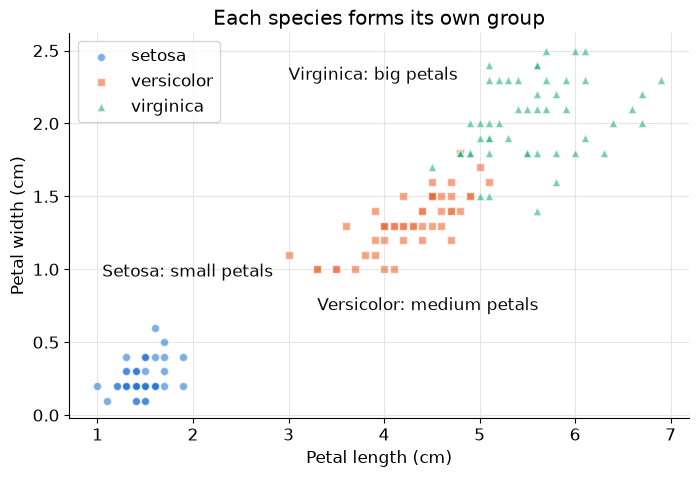

In [3]:
draw_flowers(X, y)
plt.text(1.05, 0.95, "Setosa: small petals", color="#0b0b0b")
plt.text(3.3, 0.72, "Versicolor: medium petals", color="#0b0b0b")
plt.text(3.0, 2.3, "Virginica: big petals", color="#0b0b0b")
plt.title("Each species forms its own group")
plt.legend(loc="upper left")
plt.show()

**What the chart shows:** each mark is one flower, and flowers of the same species sit close together. Setosa is far from the others, so it is easy to spot. Versicolor and virginica touch each other, so those two are harder to separate.

This is why KNN suits this data: flowers that are close together on the chart are usually the same species.

### Step 2: How does KNN work?
KNN makes a guess by looking at the most similar examples it already knows. It is like asking your closest neighbours for their opinion.

To identify a new flower, it does three things:
1. **Measure the distance** to every flower it knows. On our chart, this is simply how far apart two flowers are. A small distance means they are very similar.
2. **Pick the K closest flowers.** These are the "nearest neighbours", and K is a number that I choose.
3. **Let the neighbours vote.** The most common species wins. If K is 5 and 4 neighbours are virginica, the guess is virginica.

KNN doesn't really learn anything in advance. It just remembers all the examples and compares each new flower with them.

**A note on scale:** KNN works on distance, so measurements need to be on a similar scale. Both of ours are in centimetres and are similar sizes, so that is fine here. If one was in grams and the other in metres, the bigger numbers would decide everything, and we would rescale them first.

### Step 3: Keep some flowers aside for testing
A student who has seen the exam answers will score well, but that doesn't prove they understand the subject.
So I split the flowers into two groups:

* **Practice flowers (75%):** the examples KNN remembers
* **Test flowers (25%):** kept hidden, to check how well it handles new flowers

In [4]:
X_practice, X_test, y_practice, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

print("Practice flowers:", len(X_practice))
print("Test flowers:", len(X_test))

Practice flowers: 112
Test flowers: 38


`stratify=y` keeps the same mix of species in both groups.

### Step 4: Watch KNN identify one new flower
Here is a new flower with a petal length of 5.0 cm and a petal width of 1.7 cm. I use 5 neighbours for now. The star on the chart is the new flower, and the black circles mark its 5 closest neighbours.

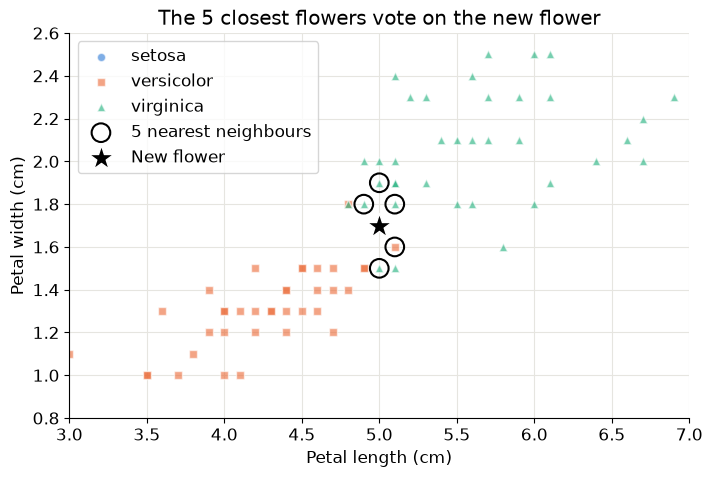

KNN's guess: virginica


,petal length (cm),petal width (cm),species,distance
83,5.1,1.6,versicolor,0.14
123,4.9,1.8,virginica,0.14
149,5.1,1.8,virginica,0.14
119,5.0,1.5,virginica,0.20
146,5.0,1.9,virginica,0.20


In [5]:
model = KNeighborsClassifier(n_neighbors=5).fit(X_practice, y_practice)

new_flower = pd.DataFrame([[5.0, 1.7]], columns=X.columns)
distances, positions = model.kneighbors(new_flower)
neighbours = X_practice.iloc[positions[0]]

draw_flowers(X_practice, y_practice)
plt.scatter(neighbours["petal length (cm)"], neighbours["petal width (cm)"], s=180, facecolor="none",
            edgecolor="black", linewidth=1.5, label="5 nearest neighbours")
plt.scatter(5.0, 1.7, marker="*", s=350, color="black", edgecolor="white", label="New flower")
plt.xlim(3, 7)
plt.ylim(0.8, 2.6)
plt.title("The 5 closest flowers vote on the new flower")
plt.legend(loc="upper left")
plt.show()

votes = neighbours.assign(species=y_practice[positions[0]], distance=distances[0].round(2))
print("KNN's guess:", model.predict(new_flower)[0])
votes

**What this shows:** the vote is 4 virginica to 1 versicolor, so KNN guesses **virginica**. The one versicolor vote is there because this flower sits near where the two species meet.

The chart is zoomed in around the new flower, so no setosa flowers appear.

This is the whole method: find the closest flowers and let them vote.

### Step 5: Choose the best number of neighbours (K)
I can't use the test flowers to choose K, because that would be like peeking at the exam. Instead I use **cross-validation**:

1. Split the practice flowers into 5 parts
2. Let each part take a turn as a mini test, while the other 4 are used as examples
3. Average the 5 scores

I try odd values of K, because an odd number of voters is less likely to tie.

Best K = 13, with a score of 98.2%


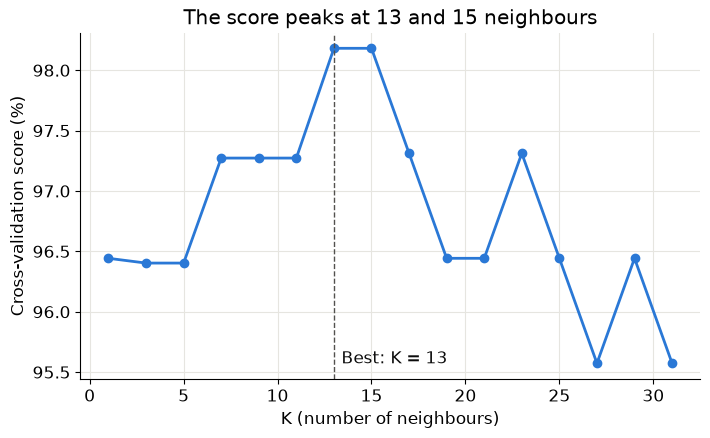

In [6]:
k_values = list(range(1, 32, 2))
scores = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores.append(cross_val_score(knn, X_practice, y_practice, cv=5).mean() * 100)

best_k = k_values[scores.index(max(scores))]
print(f"Best K = {best_k}, with a score of {max(scores):.1f}%")

plt.figure(figsize=(8, 4.5))
plt.plot(k_values, scores, "o-", color="#2a78d6", lw=2)
plt.axvline(best_k, color="#52514e", ls="--", lw=1)
plt.text(best_k + 0.4, min(scores), f"Best: K = {best_k}", color="#0b0b0b")
plt.xlabel("K (number of neighbours)")
plt.ylabel("Cross-validation score (%)")
plt.title("The score peaks at 13 and 15 neighbours")
plt.show()

**What this shows:**
* **K = 13 and K = 15 tie for the best score,** at 98.2%. I use 13 because it is the simpler choice.
* **All the scores are high,** between about 96% and 98%, because the species are well separated. The gaps are small too: one practice flower is worth less than 1%.
* **K = 1, 3 and 5 score a little lower.** With very few neighbours, one unusual flower can change the guess. This is **overfitting**.
* **The biggest values of K tend to score lowest,** because the vote starts to include flowers that aren't really similar. This is **underfitting**.

### Step 6: Test the final model
Now I check the final model on the test flowers, which it has never seen. The table shows the real species in each row and the model's guess in each column.

In [7]:
knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_practice, y_practice)
guesses = knn.predict(X_test)

print(f"Correct on test flowers: {knn.score(X_test, y_test):.1%}")
pd.crosstab(y_test, guesses, rownames=["Real species"], colnames=["Model's guess"])

Correct on test flowers: 94.7%


Model's guess,setosa,versicolor,virginica
Real species,,,
setosa,12,0,0
versicolor,0,12,1
virginica,0,1,12


**What this shows:** the model gets 36 of the 38 test flowers right, which is 94.7%.
* All 12 setosa flowers were identified correctly.
* There were 2 mistakes: 1 versicolor was guessed as virginica, and 1 virginica was guessed as versicolor. These are the two species that touch on the chart.

This score is lower than the 98.2% in Step 5, but there are only 38 test flowers, so each mistake costs about 2.6%. The test score is the one to trust, because the model had never seen these flowers.

### Step 7: Identify some new flowers
I give the model three made-up flowers and ask it to identify them.

In [8]:
new_flowers = pd.DataFrame([
    [1.5, 0.2],
    [4.2, 1.3],
    [6.0, 2.2],
], columns=X.columns)

new_flowers.assign(guess=knn.predict(new_flowers))

,petal length (cm),petal width (cm),guess
0,1.5,0.2,setosa
1,4.2,1.3,versicolor
2,6.0,2.2,virginica


### Conclusion
* KNN gets about **95%** of new flowers right, just by comparing each one with the most similar flowers it knows.
* The whole method is simple: **measure the distance, pick the K closest, and let them vote.**
* **K = 13** was chosen with cross-validation. Very small K can be misled by one unusual flower, and very large K brings in flowers that aren't really similar.
* The mistakes happen where versicolor and virginica overlap, because flowers there have neighbours from both species.
* KNN can be slow on very large datasets, because it compares each new case with every example it remembers.
* **Main lesson:** things that are similar usually belong together, and that simple idea can be enough to make good guesses.